In [1]:

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

SEED = 42

LABELS = ["Low", "Mid", "High"]
LABEL_MAP = {"Low": 0, "Mid": 1, "High": 2}

PROB_COLS = ["p_Low", "p_Mid", "p_High"]

# Review Capacity (%)
CAPACITIES = [10, 20, 30, 40, 50]

cwd = Path.cwd()

if (cwd / "splits/test.csv").exists():
    BASE = cwd

elif (cwd / "output/splits/test.csv").exists():
    BASE = cwd / "output"

else:
    raise FileNotFoundError(
        f"Cannot locate splits/test.csv. CWD: {cwd}"
    )

DATA_DIR = BASE / "splits"
PROB_DIR = BASE / "section_4_2"

RESULT_DIR = BASE / "section_4_5"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", BASE.resolve())
print("Review capacities:", CAPACITIES)
print("READY!")


Working directory: /Users/hgianee/Downloads/Maternal health risk data 2/output
Review capacities: [10, 20, 30, 40, 50]
READY!


In [2]:

def load_capacity_data(split_name):

    labels = pd.read_csv(
        DATA_DIR / f"{split_name}.csv",
        dtype={"row_id": str}
    )

    probs = pd.read_csv(
        PROB_DIR / f"full_{split_name}_probs.csv",
        dtype={"row_id": str}
    )

    assert labels["row_id"].is_unique
    assert probs["row_id"].is_unique

    assert set(labels["row_id"]) == set(
        probs["row_id"]
    ), f"row_id mismatch in {split_name}"

    merged = (
        labels[["row_id", "RiskLevel"]]
        .merge(
            probs[["row_id"] + PROB_COLS],
            on="row_id",
            how="inner",
            validate="one_to_one"
        )
        .sort_values("row_id")
        .reset_index(drop=True)
    )

    y = merged["RiskLevel"].map(
        LABEL_MAP
    ).to_numpy(dtype=int)

    assert np.isin(y, [0, 1, 2]).all()

    p = merged[PROB_COLS].to_numpy(dtype=float)

    assert np.isfinite(p).all()
    assert np.all((p >= 0) & (p <= 1))
    assert np.allclose(p.sum(axis=1), 1, atol=1e-6)

    return {
        "frame": merged,
        "y": y,
        "p": p,
        "row_ids": merged["row_id"].to_numpy()
    }


datasets = {
    split: load_capacity_data(split)
    for split in ["policy_val", "test"]
}

for split, ds in datasets.items():
    print(
        f"{split}: {len(ds['y'])} records | "
        f"High Risk: {(ds['y'] == 2).sum()}"
    )

print("\nOFFICIAL FULL XGBOOST PROBABILITIES LOADED!")


policy_val: 606 records | High Risk: 201
test: 1212 records | High Risk: 403

OFFICIAL FULL XGBOOST PROBABILITIES LOADED!


In [3]:

test_ds = datasets["test"]

y_test = test_ds["y"]
p_test = test_ds["p"]

pred = p_test.argmax(axis=1)

cm = confusion_matrix(
    y_test, pred, labels=[0, 1, 2]
)

expected_cm = np.array([
    [400, 0, 0],
    [2, 406, 1],
    [1, 3, 399]
])

print("Full XGBoost Confusion Matrix:")
print(cm)

assert np.array_equal(
    cm, expected_cm
), "ERROR: Predictions differ from Section 4.1"

print("\nPASS: SAME FULL XGBOOST AS SECTION 4.1!")


Full XGBoost Confusion Matrix:
[[400   0   0]
 [  2 406   1]
 [  1   3 399]]

PASS: SAME FULL XGBOOST AS SECTION 4.1!


In [4]:

RANKING_STRATEGIES = [
    "HighProbability",
    "ExpectedSeverity"
]


def get_ranking_scores(probs, strategy):

    if strategy == "HighProbability":
        return probs[:, 2]

    if strategy == "ExpectedSeverity":
        return (
            probs[:, 1] + 2.0 * probs[:, 2]
        )

    raise ValueError(
        f"Unknown ranking strategy: {strategy}"
    )


def rank_records(ds, strategy):

    scores = get_ranking_scores(
        ds["p"], strategy
    )

    # Highest score first.
    # Ties resolved by row_id ascending.
    order = np.lexsort(
        (ds["row_ids"], -scores)
    )

    ranks = np.empty(len(order), dtype=int)
    ranks[order] = np.arange(
        1, len(order) + 1
    )

    return scores, order, ranks


for strategy in RANKING_STRATEGIES:
    scores, order, ranks = rank_records(
        datasets["policy_val"], strategy
    )

    print(
        strategy,
        "| Top score:",
        round(float(scores[order[0]]), 5)
    )

print("\nRANKING FUNCTIONS READY!")


HighProbability | Top score: 0.99999
ExpectedSeverity | Top score: 1.99998

RANKING FUNCTIONS READY!


In [5]:

def evaluate_capacity(ds, strategy, capacity):

    y = ds["y"]

    n = len(y)
    n_high = int((y == 2).sum())

    assert n_high > 0
    assert 0 < capacity <= 100

    k = int(
        np.floor(n * capacity / 100 + 1e-9)
    )

    scores, order, ranks = rank_records(
        ds, strategy
    )

    top_indices = order[:k]

    captured_high = int(
        (y[top_indices] == 2).sum()
    )

    precision = captured_high / k
    recall = captured_high / n_high

    prevalence = n_high / n

    oracle_high = min(k, n_high)

    return {
        "Strategy": strategy,
        "Capacity": capacity,
        "N_Reviewed": k,
        "Captured_High": captured_high,
        "Precision_at_K": precision,
        "High_Recall_at_K": recall,
        "Lift_vs_Random": precision / prevalence,
        "Oracle_Recall_at_K": oracle_high / n_high,
        "Random_Expected_Recall": k / n,
        "Random_Expected_Precision": prevalence
    }


# Example: K = 20% on Policy Validation
demo = evaluate_capacity(
    datasets["policy_val"],
    "HighProbability",
    capacity=20
)

display(
    pd.DataFrame([demo]).round(5)
)

print("CAPACITY METRICS READY!")


,Strategy,Capacity,N_Reviewed,Captured_High,Precision_at_K,High_Recall_at_K,Lift_vs_Random,Oracle_Recall_at_K,Random_Expected_Recall,Random_Expected_Precision
0,HighProbability,20,121,121,1.0,0.60199,3.01493,0.60199,0.19967,0.33168


CAPACITY METRICS READY!


In [6]:

validation_results = []

for strategy in RANKING_STRATEGIES:

    for k in CAPACITIES:

        result = evaluate_capacity(
            datasets["policy_val"],
            strategy,
            k
        )

        validation_results.append(result)


validation_df = pd.DataFrame(
    validation_results
)

display(
    validation_df[
        [
            "Strategy",
            "Capacity",
            "N_Reviewed",
            "Captured_High",
            "Precision_at_K",
            "High_Recall_at_K",
            "Oracle_Recall_at_K"
        ]
    ].round(5)
)

validation_df.to_csv(
    RESULT_DIR / "capacity_validation_all_strategies.csv",
    index=False
)

print("CAPACITY VALIDATION COMPLETED!")


,Strategy,Capacity,N_Reviewed,Captured_High,Precision_at_K,High_Recall_at_K,Oracle_Recall_at_K
0,HighProbability,10,60,60,1.00000,0.29851,0.29851
1,HighProbability,20,121,121,1.00000,0.60199,0.60199
2,HighProbability,30,181,181,1.00000,0.90050,0.90050
3,HighProbability,40,242,199,0.82231,0.99005,1.00000
4,HighProbability,50,303,201,0.66337,1.00000,1.00000
5,ExpectedSeverity,10,60,60,1.00000,0.29851,0.29851
6,ExpectedSeverity,20,121,121,1.00000,0.60199,0.60199
7,ExpectedSeverity,30,181,181,1.00000,0.90050,0.90050
8,ExpectedSeverity,40,242,198,0.81818,0.98507,1.00000
9,ExpectedSeverity,50,303,199,0.65677,0.99005,1.00000


CAPACITY VALIDATION COMPLETED!


In [7]:

# Mean recall across all review capacities
summary = (
    validation_df
    .groupby("Strategy", as_index=False)
    .agg(
        Mean_Recall_at_K=(
            "High_Recall_at_K", "mean"
        ),
        Mean_Precision_at_K=(
            "Precision_at_K", "mean"
        ),
        Mean_Lift=(
            "Lift_vs_Random", "mean"
        )
    )
)

# Tie-breakers: Recall@20, then Recall@10
recall_wide = validation_df.pivot(
    index="Strategy",
    columns="Capacity",
    values="High_Recall_at_K"
)

summary["Recall_at_20"] = (
    summary["Strategy"].map(recall_wide[20])
)

summary["Recall_at_10"] = (
    summary["Strategy"].map(recall_wide[10])
)

# Prefer HighProbability on a complete tie
summary["Tie_Priority"] = (
    summary["Strategy"]
    .map({
        "HighProbability": 0,
        "ExpectedSeverity": 1
    })
)

summary = (
    summary.sort_values(
        [
            "Mean_Recall_at_K",
            "Recall_at_20",
            "Recall_at_10",
            "Tie_Priority"
        ],
        ascending=[False, False, False, True],
        kind="mergesort"
    )
    .reset_index(drop=True)
)

display(
    summary.drop(columns="Tie_Priority").round(5)
)

selected_strategy = summary.iloc[0]["Strategy"]

print("\nSELECTED RANKING STRATEGY:", selected_strategy)

selection_metadata = {
    "section": "4.5 Capacity-Constrained Prioritisation",
    "model": "Full XGBoost",
    "probabilities": "Calibrated probabilities from Section 4.2",
    "selection_split": "policy_val",
    "selected_strategy": selected_strategy,
    "selection_rule": (
        "Highest mean High-Risk Recall@K across "
        "K=10,20,30,40,50; tie-break Recall@20, "
        "then Recall@10, then HighProbability."
    ),
    "review_capacities": CAPACITIES,
    "ranking_tiebreaker": "row_id ascending",
    "top_k_rule": "floor(N * K / 100)",
    "class_order": LABELS,
    "seed": SEED
}

with open(
    RESULT_DIR / "selected_capacity_policy.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selection_metadata,
        f,
        indent=2,
        ensure_ascii=False
    )

summary.to_csv(
    RESULT_DIR / "capacity_validation_ranking.csv",
    index=False
)

print("\nCAPACITY POLICY LOCKED!")


,Strategy,Mean_Recall_at_K,Mean_Precision_at_K,Mean_Lift,Recall_at_20,Recall_at_10
0,HighProbability,0.75821,0.89714,2.70480,0.60199,0.29851
1,ExpectedSeverity,0.75522,0.89499,2.69833,0.60199,0.29851



SELECTED RANKING STRATEGY: HighProbability

CAPACITY POLICY LOCKED!


In [8]:

test_ds = datasets["test"]

test_results = []

# Evaluate both methods for transparent comparison,
# but do not select a new policy from the test set.
for strategy in RANKING_STRATEGIES:

    for k in CAPACITIES:

        result = evaluate_capacity(
            test_ds,
            strategy,
            k
        )

        test_results.append(result)


test_all_df = pd.DataFrame(test_results)

selected_test_df = (
    test_all_df[
        test_all_df["Strategy"] == selected_strategy
    ]
    .copy()
    .sort_values("Capacity")
    .reset_index(drop=True)
)

display(
    selected_test_df[
        [
            "Capacity",
            "N_Reviewed",
            "Captured_High",
            "Precision_at_K",
            "High_Recall_at_K",
            "Lift_vs_Random",
            "Oracle_Recall_at_K"
        ]
    ].round(5)
)

test_all_df.to_csv(
    RESULT_DIR / "capacity_test_all_rankings.csv",
    index=False
)

selected_test_df.to_csv(
    RESULT_DIR / "capacity_test_selected_policy.csv",
    index=False
)

print("\nSELECTED POLICY:", selected_strategy)
print("CAPACITY TEST EVALUATION COMPLETED!")


,Capacity,N_Reviewed,Captured_High,Precision_at_K,High_Recall_at_K,Lift_vs_Random,Oracle_Recall_at_K
0,10,121,121,1.00000,0.30025,3.00744,0.30025
1,20,242,242,1.00000,0.60050,3.00744,0.60050
2,30,363,363,1.00000,0.90074,3.00744,0.90074
3,40,484,402,0.83058,0.99752,2.49792,1.00000
4,50,606,403,0.66502,1.00000,2.00000,1.00000



SELECTED POLICY: HighProbability
CAPACITY TEST EVALUATION COMPLETED!


In [9]:

N_RANDOM_RUNS = 500

rng = np.random.default_rng(SEED)

y = test_ds["y"]

n = len(y)
n_high = int((y == 2).sum())

random_rows = []

for repetition in range(N_RANDOM_RUNS):

    # One random order per repetition.
    # Nested selections across increasing K.
    random_order = rng.permutation(n)

    for capacity in CAPACITIES:

        k = int(
            np.floor(n * capacity / 100 + 1e-9)
        )

        top_indices = random_order[:k]

        captured = int(
            (y[top_indices] == 2).sum()
        )

        random_rows.append({
            "Repetition": repetition,
            "Capacity": capacity,
            "Captured_High": captured,
            "Precision_at_K": captured / k,
            "High_Recall_at_K": captured / n_high
        })


random_df = pd.DataFrame(random_rows)

random_summary = (
    random_df.groupby(
        "Capacity", as_index=False
    )
    .agg(
        Random_Mean_Precision=(
            "Precision_at_K", "mean"
        ),
        Random_Mean_Recall=(
            "High_Recall_at_K", "mean"
        ),
        Random_Recall_SD=(
            "High_Recall_at_K", "std"
        ),
        Random_Captured_Mean=(
            "Captured_High", "mean"
        )
    )
)

display(random_summary.round(5))

random_df.to_csv(
    RESULT_DIR / "capacity_random_repetitions.csv",
    index=False
)

random_summary.to_csv(
    RESULT_DIR / "capacity_random_summary.csv",
    index=False
)

print("RANDOM BASELINE COMPLETED!")


,Capacity,Random_Mean_Precision,Random_Mean_Recall,Random_Recall_SD,Random_Captured_Mean
0,10,0.33349,0.10013,0.01226,40.352
1,20,0.33312,0.20004,0.01627,80.616
2,30,0.33234,0.29935,0.01875,120.638
3,40,0.33258,0.39942,0.02016,160.968
4,50,0.33260,0.50014,0.02014,201.558


RANDOM BASELINE COMPLETED!


In [10]:

final_table = selected_test_df.merge(
    random_summary[
        [
            "Capacity",
            "Random_Mean_Precision",
            "Random_Mean_Recall"
        ]
    ],
    on="Capacity",
    validate="one_to_one"
)

display(
    final_table[
        [
            "Capacity",
            "N_Reviewed",
            "Captured_High",
            "Precision_at_K",
            "High_Recall_at_K",
            "Random_Mean_Recall",
            "Oracle_Recall_at_K",
            "Lift_vs_Random"
        ]
    ].round(5)
)

final_table.to_csv(
    RESULT_DIR / "table_16_capacity_test.csv",
    index=False
)

print("MAIN REPORT TABLE SAVED!")


,Capacity,N_Reviewed,Captured_High,Precision_at_K,High_Recall_at_K,Random_Mean_Recall,Oracle_Recall_at_K,Lift_vs_Random
0,10,121,121,1.00000,0.30025,0.10013,0.30025,3.00744
1,20,242,242,1.00000,0.60050,0.20004,0.60050,3.00744
2,30,363,363,1.00000,0.90074,0.29935,0.90074,3.00744
3,40,484,402,0.83058,0.99752,0.39942,1.00000,2.49792
4,50,606,403,0.66502,1.00000,0.50014,1.00000,2.00000


MAIN REPORT TABLE SAVED!


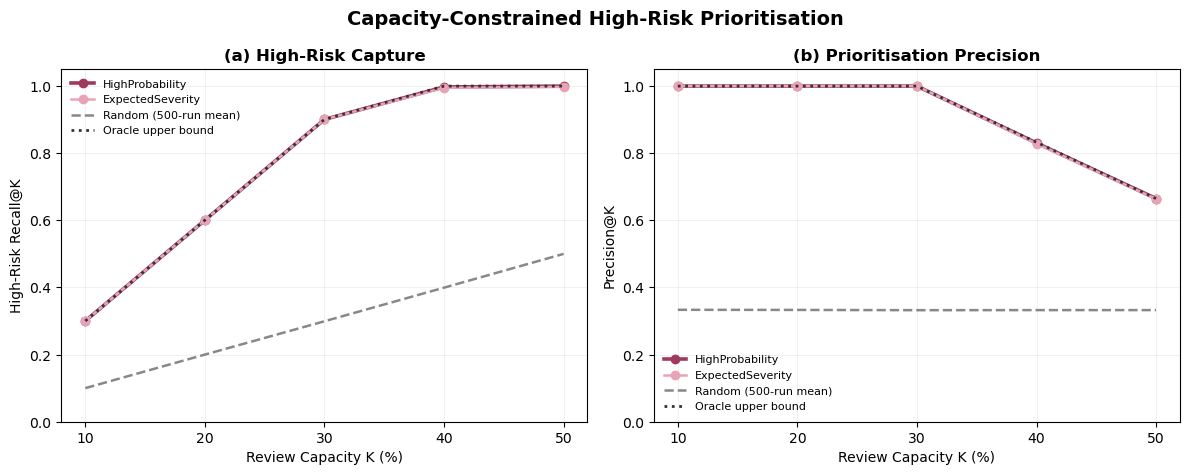

FIGURE 11 SAVED!


In [11]:

# CELL 11 — Capacity-Aware Prioritisation Figure

PINK_DARK = "#9F3A5B"
PINK_LIGHT = "#E9A3B7"
GRAY = "#888888"
BLACK = "#333333"

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.8)
)

colors = {
    selected_strategy: PINK_DARK
}

other_strategy = next(
    s for s in RANKING_STRATEGIES
    if s != selected_strategy
)

colors[other_strategy] = PINK_LIGHT

# Panel (a): Recall@K
ax = axes[0]

for strategy in RANKING_STRATEGIES:

    df = (
        test_all_df[
            test_all_df["Strategy"] == strategy
        ]
        .sort_values("Capacity")
    )

    ax.plot(
        df["Capacity"],
        df["High_Recall_at_K"],
        marker="o",
        linewidth=2.6 if strategy == selected_strategy else 1.8,
        color=colors[strategy],
        label=strategy
    )

ax.plot(
    random_summary["Capacity"],
    random_summary["Random_Mean_Recall"],
    "--",
    color=GRAY,
    linewidth=1.8,
    label="Random (500-run mean)"
)

ax.plot(
    selected_test_df["Capacity"],
    selected_test_df["Oracle_Recall_at_K"],
    ":",
    color=BLACK,
    linewidth=2,
    label="Oracle upper bound"
)

ax.set_title(
    "(a) High-Risk Capture",
    fontweight="bold"
)

ax.set_xlabel("Review Capacity K (%)")
ax.set_ylabel("High-Risk Recall@K")


# Panel (b): Precision@K
ax = axes[1]

for strategy in RANKING_STRATEGIES:

    df = (
        test_all_df[
            test_all_df["Strategy"] == strategy
        ]
        .sort_values("Capacity")
    )

    ax.plot(
        df["Capacity"],
        df["Precision_at_K"],
        marker="o",
        linewidth=2.6 if strategy == selected_strategy else 1.8,
        color=colors[strategy],
        label=strategy
    )

ax.plot(
    random_summary["Capacity"],
    random_summary["Random_Mean_Precision"],
    "--",
    color=GRAY,
    linewidth=1.8,
    label="Random (500-run mean)"
)

oracle_precision = np.minimum(
    selected_test_df["N_Reviewed"].to_numpy(),
    (y_test == 2).sum()
) / selected_test_df["N_Reviewed"].to_numpy()

ax.plot(
    selected_test_df["Capacity"],
    oracle_precision,
    ":",
    color=BLACK,
    linewidth=2,
    label="Oracle upper bound"
)

ax.set_title(
    "(b) Prioritisation Precision",
    fontweight="bold"
)

ax.set_xlabel("Review Capacity K (%)")
ax.set_ylabel("Precision@K")


# Shared appearance
for ax in axes:
    ax.set_xticks(CAPACITIES)
    ax.set_xlim(8, 52)
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.17)
    ax.legend(
        frameon=False,
        fontsize=8,
        loc="best"
    )

fig.suptitle(
    "Capacity-Constrained High-Risk Prioritisation",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "capacity_prioritisation_two_panel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("FIGURE 11 SAVED!")


In [12]:

# CELL 12 — Export Capacity Ranking Artifacts

for split_name, ds in datasets.items():

    scores, order, ranks = rank_records(
        ds, selected_strategy
    )

    exports = []

    n = len(ds["y"])

    for capacity in CAPACITIES:

        k = int(
            np.floor(n * capacity / 100 + 1e-9)
        )

        selected_for_review = ranks <= k

        export = pd.DataFrame({
            "row_id": ds["row_ids"],
            "RiskLevel": np.array(LABELS)[ds["y"]],
            "Capacity": capacity,
            "Ranking_Strategy": selected_strategy,
            "Ranking_Score": scores,
            "Rank": ranks,
            "Selected_For_Review": selected_for_review,
            "p_Low": ds["p"][:, 0],
            "p_Mid": ds["p"][:, 1],
            "p_High": ds["p"][:, 2]
        })

        assert len(export) == n
        assert export["row_id"].is_unique
        assert int(selected_for_review.sum()) == k

        exports.append(export)

    combined = pd.concat(
        exports,
        ignore_index=True
    )

    assert len(combined) == (
        n * len(CAPACITIES)
    )

    assert not combined.duplicated(
        ["Capacity", "row_id"]
    ).any()

    filename = (
        f"capacity_{split_name}_rankings_long.csv"
    )

    combined.to_csv(
        RESULT_DIR / filename,
        index=False
    )

    print(
        f"SAVED: {filename}, "
        f"{len(combined)} rows"
    )

print("\nCAPACITY ARTIFACTS EXPORTED!")


SAVED: capacity_policy_val_rankings_long.csv, 3030 rows
SAVED: capacity_test_rankings_long.csv, 6060 rows

CAPACITY ARTIFACTS EXPORTED!


In [13]:

# CELL 13 — Final Capacity Audit

for split_name, ds in datasets.items():

    n = len(ds["y"])
    n_high = int((ds["y"] == 2).sum())

    _, order, ranks = rank_records(
        ds, selected_strategy
    )

    previous_selected = set()
    previous_captured = -1

    for capacity in CAPACITIES:

        k = int(
            np.floor(n * capacity / 100 + 1e-9)
        )

        selected = ranks <= k

        assert selected.sum() == k

        selected_ids = set(
            ds["row_ids"][selected]
        )

        assert previous_selected.issubset(
            selected_ids
        )

        previous_selected = selected_ids

        captured = int(
            ((ds["y"] == 2) & selected).sum()
        )

        assert captured <= min(k, n_high)
        assert captured >= previous_captured

        previous_captured = captured

        result = evaluate_capacity(
            ds, selected_strategy, capacity
        )

        assert result["Captured_High"] == captured
        assert np.isclose(
            result["Oracle_Recall_at_K"],
            min(k, n_high) / n_high
        )

        assert np.isclose(
            result["Random_Expected_Recall"],
            k / n
        )

    print(
        f"PASS: {split_name} — Top-K counts, "
        "nested ranking and recall bounds"
    )

print("\nALL CAPACITY CHECKS PASSED!")
print("Selected ranking strategy:", selected_strategy)
print("Output folder:", RESULT_DIR.resolve())


PASS: policy_val — Top-K counts, nested ranking and recall bounds
PASS: test — Top-K counts, nested ranking and recall bounds

ALL CAPACITY CHECKS PASSED!
Selected ranking strategy: HighProbability
Output folder: /Users/hgianee/Downloads/Maternal health risk data 2/output/section_4_5
